# Reinforcement learning on a warehouse grid: Q-learning, SARSA and policy gradients

A robot must reach the **packaging area** of an 11×11 warehouse as fast as possible without
hitting a shelf. The problem is small enough to be solved *exactly*, which lets this notebook do
something a single training run cannot: **measure how far each learning algorithm is from the
true optimum**, over many random seeds.

**Questions**

1. Does tabular Q-learning find the shortest paths, and how fast? (Section 4)
2. Why does SARSA, which has the same update cost, behave so differently? (Sections 4-5)
3. How sensitive are both to the learning rate α, the exploration rate ε and the discount γ? (Section 6)
4. What changes when the environment is stochastic? (Section 7)
5. How does a policy-gradient method (REINFORCE) compare, and what does a baseline buy? (Section 8)

All code lives in [`rl_warehouse.py`](rl_warehouse.py); this notebook only calls it, runs the
experiments and plots. Every random number is seeded, so the results are reproducible.

In [1]:
import json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import rl_warehouse as rl
from rl_warehouse import (WarehouseEnv, value_iteration, epsilon_soft_optimal, shortest_lengths,
                          train_td, train_reinforce, evaluate_greedy, greedy_path,
                          monte_carlo_eval, linear_decay, smooth, mean_ci, draw_grid, to_rc, to_state)

FIG, RES = Path("figures"), Path("results")
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
results = {}                      # everything quoted in the README / report is stored here

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "legend.frameon": False})
PALETTE = ["#1f5fa8", "#d98324", "#2e9e5b", "#b5483a", "#8e44ad"]

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=170, bbox_inches="tight")

GAMMA, EPS = 0.9, 0.1             # defaults used unless a section varies them
SEEDS = range(20)

## 1. The environment as a Markov decision process

* **States** $S$: the 121 grid squares; **actions** $A=\{\text{up},\text{right},\text{down},\text{left}\}$.
* **Transitions**: deterministic (moving into the outer wall leaves the robot in place). Section 7 adds a
  *slip* probability.
* **Rewards** $R(s')$, received on entering $s'$: **+100** at the packaging area, **−1** on every free
  square (so shorter is better), **−100** on a shelf, which also ends the episode.
* **Discount** $\gamma = 0.9$. Episodes start on a uniformly random free square (56 of them).

Terminal states have value 0 and are never bootstrapped from.

56 free squares, 65 terminal squares (1 goal + 64 shelves)


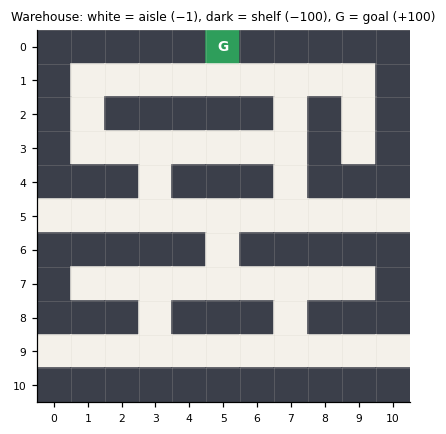

In [2]:
env = WarehouseEnv()
print(f"{len(env.free_states)} free squares, {int(env.terminal.sum())} terminal squares "
      f"(1 goal + {int(env.terminal.sum()) - 1} shelves)")

fig, ax = plt.subplots(figsize=(4.4, 4.4))
draw_grid(ax, env, title="Warehouse: white = aisle (−1), dark = shelf (−100), G = goal (+100)")
ax.grid(False); ax.set_title(ax.get_title(), fontsize=8)
savefig(fig, "fig_env"); plt.show()

## 2. Ground truth: solving the MDP exactly

Because the model is known and tiny, the Bellman optimality equation can be solved by
**value iteration**:

$$Q^*(s,a)=\sum_{s'}P(s'\mid s,a)\,\big[R(s')+\gamma V^*(s')\big],\qquad V^*(s)=\max_a Q^*(s,a).$$

As an independent check, a breadth-first search (BFS) gives the true shortest-path length from every
square. With a −1 step cost and a discounted goal reward, the greedy policy for $Q^*$ must follow
shortest paths. This gives us two oracles to grade the learners against.

value iteration converged in 19 sweeps
greedy(Q*): reaches goal from 100% of starts, shortest path from 100%
longest shortest path: 18 steps


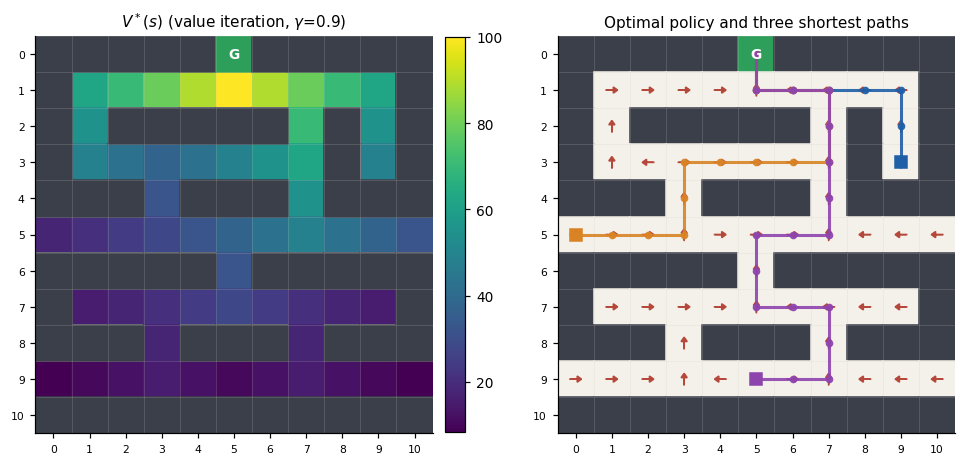

In [3]:
Q_STAR, V_STAR, PI_STAR, n_iter = value_iteration(env, GAMMA)
DIST = shortest_lengths(env)

succ, opt, exc = evaluate_greedy(env, Q_STAR, DIST)
print(f"value iteration converged in {n_iter} sweeps")
print(f"greedy(Q*): reaches goal from {succ:.0%} of starts, shortest path from {opt:.0%}")
assert succ == 1.0 and opt == 1.0, "value iteration and BFS disagree"
print(f"longest shortest path: {int(DIST[env.free_states].max())} steps")

results["oracle"] = dict(vi_sweeps=int(n_iter), free_states=int(len(env.free_states)),
                         max_shortest_path=int(DIST[env.free_states].max()))

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
draw_grid(axes[0], env, values=V_STAR, title=r"$V^*(s)$ (value iteration, $\gamma$=0.9)")
paths = [greedy_path(env, Q_STAR, to_state(*rc))[0] for rc in [(3, 9), (5, 0), (9, 5)]]
draw_grid(axes[1], env, policy=PI_STAR, paths=paths,
          title="Optimal policy and three shortest paths")
for a in axes: a.grid(False)
fig.tight_layout(); savefig(fig, "fig_optimal"); plt.show()

## 3. Learning without the model

Both algorithms learn a table $Q(s,a)$ from sampled transitions $(s,a,r,s')$ with an
**ε-greedy** behaviour policy: *ε is the probability of a random action* (the notebook this project
started from used ε as the probability of the greedy action; the convention is now the standard one).

| | update target | policy it evaluates |
|---|---|---|
| **Q-learning** (off-policy) | $r+\gamma\max_{a'}Q(s',a')$ | the greedy policy, $\to Q^*$ |
| **SARSA** (on-policy) | $r+\gamma\,Q(s',a')$, $a'\sim\varepsilon$-greedy | the ε-greedy policy itself, $\to Q^*_\varepsilon$ |

with $Q(s,a)\leftarrow Q(s,a)+\alpha\,[\text{target}-Q(s,a)]$. Notice that SARSA's fixed point
$Q^*_\varepsilon$ is *not* $Q^*$: it is the best action-value function achievable **while still exploring**.
We can compute it exactly too (`epsilon_soft_optimal`), so each learner is graded against *its own* target.

First, the original experiment (α=0.9, γ=0.9, ε=0.1, 1000 episodes, one run) to check that the rewritten
code reproduces the original behaviour:

start (3, 9): goal  in  7 steps (shortest = 7)
start (5, 0): goal  in 14 steps (shortest = 14)
start (9, 5): goal  in 17 steps (shortest = 17)
start (5, 2): goal  in 12 steps (shortest = 12)


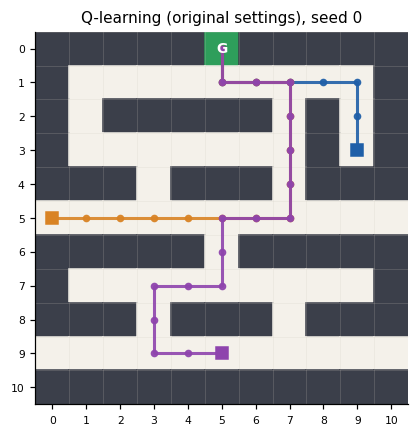

all 56 starts: success 100%, optimal 98%, mean excess steps 0.04


In [4]:
Q0, h0 = train_td(env, "q", episodes=1000, alpha=0.9, gamma=GAMMA, epsilon=EPS, seed=0)
for start in [(3, 9), (5, 0), (9, 5), (5, 2)]:
    s0 = to_state(*start)
    path, out = greedy_path(env, Q0, s0)
    print(f"start {start}: {out:5s} in {len(path)-1:2d} steps (shortest = {int(DIST[s0])})")

paths = [greedy_path(env, Q0, to_state(*rc))[0] for rc in [(3, 9), (5, 0), (9, 5)]]
fig, ax = plt.subplots(figsize=(4.4, 4.4))
draw_grid(ax, env, paths=paths, title="Q-learning (original settings), seed 0")
ax.grid(False); savefig(fig, "fig_paths"); plt.show()
sc, op, ex = evaluate_greedy(env, Q0, DIST)
print(f"all 56 starts: success {sc:.0%}, optimal {op:.0%}, mean excess steps {ex:.2f}")

## 4. Q-learning vs SARSA over 20 seeds

A single run says little. Here each configuration is trained for 2000 episodes from 20 independent seeds.
Every 50 episodes the **greedy policy** is graded exactly from all 56 starts (fraction of starts whose
path is a true shortest path), and the error of its value function $V(s)=\max_a Q(s,a)$ is measured against
the learner's own exact target. Bands are 95% confidence intervals across seeds.

done in 34s


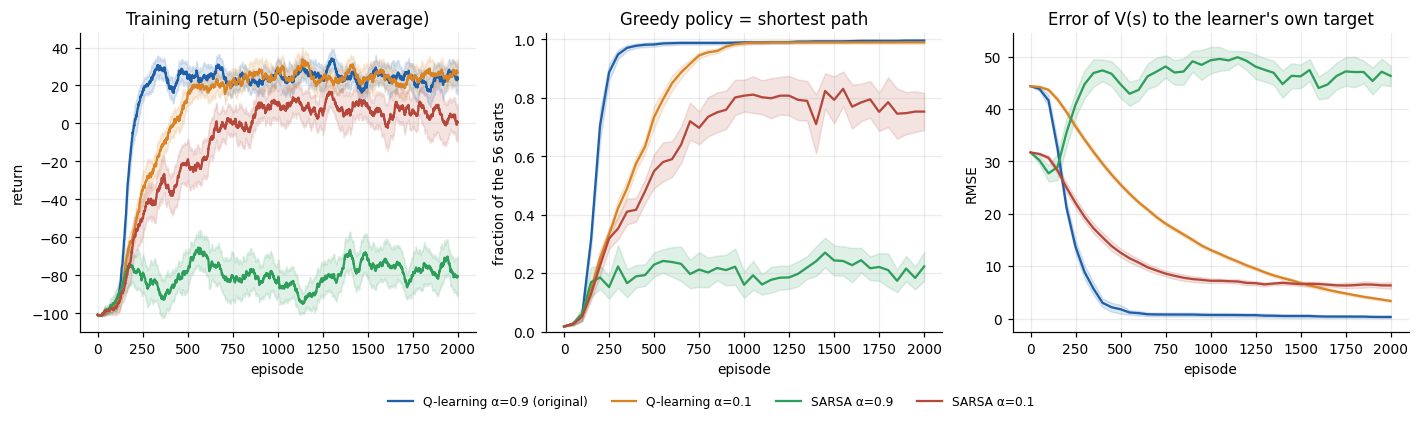

configuration                      reaches goal   shortest path  episodes to 90%
Q-learning α=0.9 (original)        1.00 ±0.00      1.00 ±0.00              300
Q-learning α=0.1                   1.00 ±0.00      0.99 ±0.00              700


SARSA α=0.9                        0.24 ±0.06      0.22 ±0.05             None
SARSA α=0.1                        0.82 ±0.05      0.75 ±0.06             None


In [5]:
EPISODES = 2000
configs = {
    "Q-learning α=0.9 (original)": dict(algo="q",     alpha=0.9),
    "Q-learning α=0.1":            dict(algo="q",     alpha=0.1),
    "SARSA α=0.9":                 dict(algo="sarsa", alpha=0.9),
    "SARSA α=0.1":                 dict(algo="sarsa", alpha=0.1),
}
Q_EPS = epsilon_soft_optimal(env, GAMMA, EPS)

t0 = time.time()
runs = {}
for name, cfg in configs.items():
    target = Q_STAR if cfg["algo"] == "q" else Q_EPS
    H, F = [], []
    for sd in SEEDS:
        Q, h = train_td(env, cfg["algo"], EPISODES, cfg["alpha"], GAMMA, EPS, seed=sd,
                        eval_every=50, dist=DIST, q_target=target)
        H.append(h); F.append(Q)
    runs[name] = (H, F)
print(f"done in {time.time()-t0:.0f}s")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for (name, (H, F)), col in zip(runs.items(), PALETTE):
    ret = np.array([smooth(h.returns, 50) for h in H])
    m, c = mean_ci(ret); x = np.arange(len(m))
    axes[0].plot(x, m, color=col, label=name); axes[0].fill_between(x, m - c, m + c, color=col, alpha=.15)
    ev = H[0].eval_episodes
    m, c = mean_ci(np.array([h.eval_optimal for h in H]))
    axes[1].plot(ev, m, color=col, label=name); axes[1].fill_between(ev, m - c, m + c, color=col, alpha=.15)
    m, c = mean_ci(np.array([h.eval_rmse for h in H]))
    axes[2].plot(ev, m, color=col, label=name); axes[2].fill_between(ev, m - c, m + c, color=col, alpha=.15)
axes[0].set(title="Training return (50-episode average)", xlabel="episode", ylabel="return")
axes[1].set(title="Greedy policy = shortest path", xlabel="episode", ylabel="fraction of the 56 starts", ylim=(0, 1.02))
axes[2].set(title="Error of V(s) to the learner's own target", xlabel="episode", ylabel="RMSE")
h_, l_ = axes[1].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.07))
fig.tight_layout(); savefig(fig, "fig_learning"); plt.show()

# final metrics
results["learning"] = {}
print(f"{'configuration':32s} {'reaches goal':>14s} {'shortest path':>15s} {'episodes to 90%':>16s}")
for name, (H, F) in runs.items():
    ev = np.array([evaluate_greedy(env, Q, DIST) for Q in F])
    (ms, cs), (mo, co) = mean_ci(ev[:, 0]), mean_ci(ev[:, 1])
    curve = np.mean([h.eval_optimal for h in H], axis=0)
    hit = np.flatnonzero(curve >= 0.9)
    ep90 = int(H[0].eval_episodes[hit[0]]) if len(hit) else None
    online = float(np.mean([h.returns[-200:].mean() for h in H]))
    results["learning"][name] = dict(success=float(ms), success_ci=float(cs), optimal=float(mo),
                                     optimal_ci=float(co), ep90=ep90, online_return=online)
    print(f"{name:32s} {ms:6.2f} ±{cs:4.2f}   {mo:7.2f} ±{co:4.2f}   {str(ep90):>14s}")

**Reading the figure.** Q-learning's greedy policy becomes optimal quickly *whatever* α is, while its value
table is still far from $Q^*$: **the policy converges long before the values do**, because only the *ordering*
of the four actions matters. SARSA is much more fragile. The next section shows why this is not a bug.

## 5. Why SARSA struggles here: exploration is dangerous

SARSA learns the value of the policy it *follows*, exploration included. In this warehouse, almost every
aisle is lined with shelves, so a random step is likely fatal (−100). The exact $V^*_\varepsilon$ makes
this visible:

free squares whose exploring-agent value V*_ε is negative: 28/56
greedy(Q*_ε) is a shortest path from 100% of starts -> SARSA's *target* is fine; its sample-based estimate is the problem


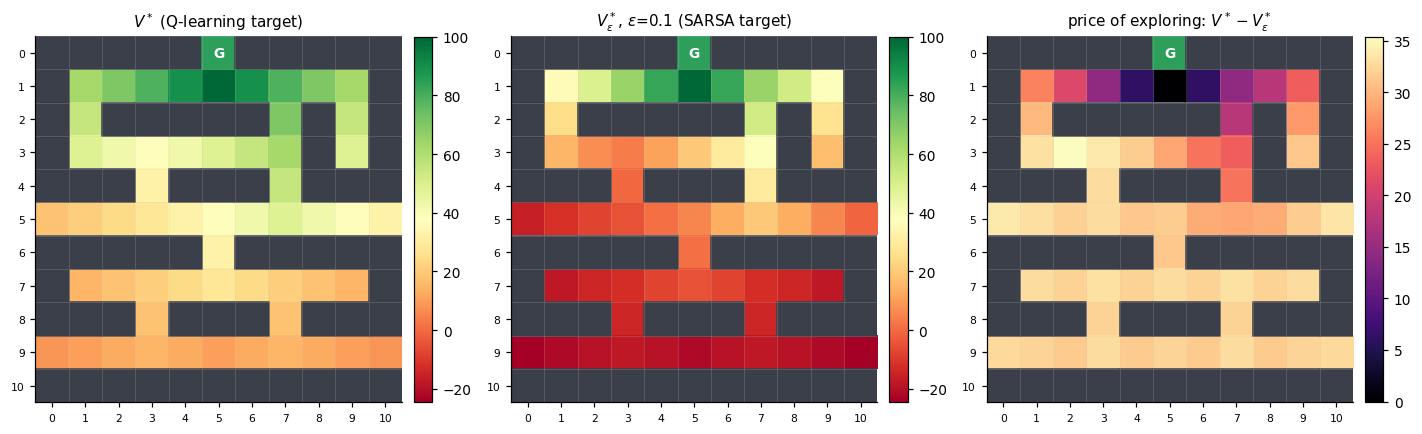

{'goal': '82.1%', 'loop': '17.9%', 'crash': '0.0%'}


In [6]:
V_EPS = Q_EPS.max(1)
fr = env.free_states
n_neg = int((V_EPS[fr] < 0).sum())
print(f"free squares whose exploring-agent value V*_ε is negative: {n_neg}/{len(fr)}")
print(f"greedy(Q*_ε) is a shortest path from {evaluate_greedy(env, Q_EPS, DIST)[1]:.0%} of starts "
      "-> SARSA's *target* is fine; its sample-based estimate is the problem")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.0))
vmin, vmax = min(V_STAR[fr].min(), V_EPS[fr].min()), max(V_STAR[fr].max(), V_EPS[fr].max())
for ax, v, t in zip(axes[:2], [V_STAR, V_EPS], [r"$V^*$ (Q-learning target)", r"$V^*_\varepsilon$, $\varepsilon$=0.1 (SARSA target)"]):
    draw_grid(ax, env, values=v, title=t, cmap="RdYlGn"); ax.grid(False)
    ax.images[0].set_clim(vmin, vmax)
draw_grid(axes[2], env, values=V_STAR - V_EPS, title=r"price of exploring: $V^*-V^*_\varepsilon$", cmap="magma"); axes[2].grid(False)
fig.tight_layout(); savefig(fig, "fig_values"); plt.show()

# how do SARSA's greedy policies fail?
H, F = runs["SARSA α=0.1"]
counts = {"goal": 0, "loop": 0, "crash": 0}
for Q in F:
    for s0 in fr:
        counts[greedy_path(env, Q, int(s0))[1]] += 1
tot = sum(counts.values())
print({k: f"{v/tot:.1%}" for k, v in counts.items()})
H, F = runs["Q-learning α=0.1"]
countsq = {"goal": 0, "loop": 0, "crash": 0}
for Q in F:
    for s0 in fr:
        countsq[greedy_path(env, Q, int(s0))[1]] += 1
results["values"] = dict(neg_states=n_neg, free=int(len(fr)),
                         vmin_eps=float(V_EPS[fr].min()), vmax_eps=float(V_EPS[fr].max()),
                         sarsa_failures={k: v / tot for k, v in counts.items()},
                         q_failures={k: v / tot for k, v in countsq.items()})

In the lower half of the warehouse the exploring agent is expected to **crash before reaching the goal**
($V^*_\varepsilon<0$ although $V^*>0$). Greedy actions there differ by a few units of value, and a single
−100 sample moves a SARSA estimate by $\alpha\cdot 100$. Q-learning's $\max$ target ignores what exploration
would do next, so its estimates are far less noisy. SARSA's failures are almost all **loops** (the greedy policy
oscillating between two squares), not crashes. Lowering α (or ε) shrinks the noise; this is the usual
bias-variance trade-off between on- and off-policy targets, and a good reason to *measure* instead of assuming.

## 6. Sensitivity to α, ε and γ

*Grid:* α × ε, 1000 episodes, 8 seeds per cell; the metric is the fraction of starts whose greedy
path is a shortest path. *Line plot:* the discount factor γ.

done in 84s


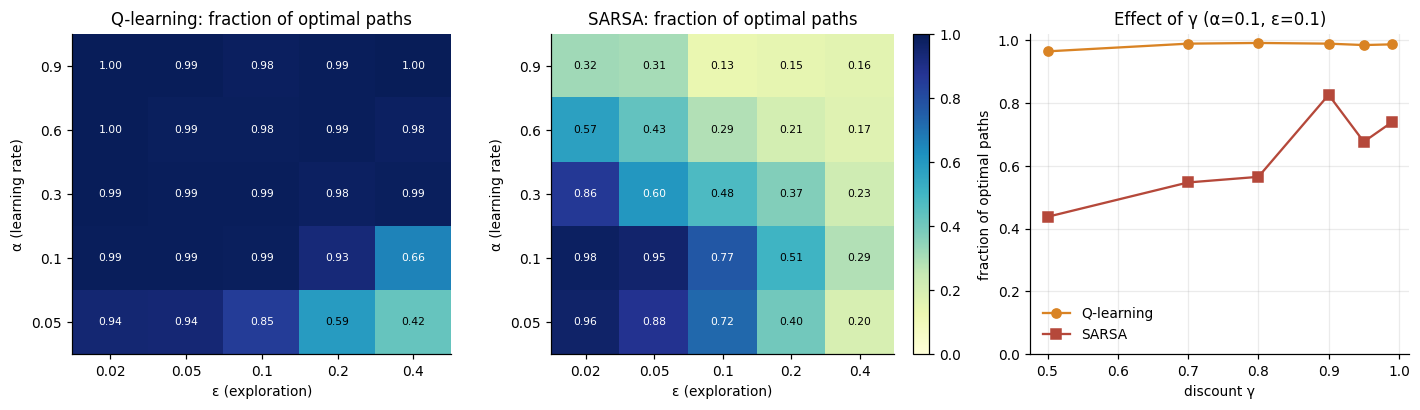

In [7]:
ALPHAS = [0.05, 0.1, 0.3, 0.6, 0.9]
EPSS   = [0.02, 0.05, 0.1, 0.2, 0.4]
GRID_SEEDS = range(8)

def grid(algo):
    M = np.zeros((len(ALPHAS), len(EPSS)))
    for i, a in enumerate(ALPHAS):
        for j, e in enumerate(EPSS):
            M[i, j] = np.mean([evaluate_greedy(env, train_td(env, algo, 1000, a, GAMMA, e, seed=s)[0], DIST)[1]
                               for s in GRID_SEEDS])
    return M

t0 = time.time()
GQ, GS = grid("q"), grid("sarsa")

GAMMAS = [0.5, 0.7, 0.8, 0.9, 0.95, 0.99]
gam = {"q": [], "sarsa": []}
for g in GAMMAS:
    for algo in gam:
        gam[algo].append(np.mean([evaluate_greedy(env, train_td(env, algo, 2000, 0.1, g, EPS, seed=s)[0], DIST)[1]
                                  for s in GRID_SEEDS]))
print(f"done in {time.time()-t0:.0f}s")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, M, t in zip(axes[:2], [GQ, GS], ["Q-learning", "SARSA"]):
    im = ax.imshow(M, vmin=0, vmax=1, cmap="YlGnBu", origin="lower", aspect="auto")
    ax.set(xticks=range(len(EPSS)), xticklabels=EPSS, yticks=range(len(ALPHAS)), yticklabels=ALPHAS,
           xlabel="ε (exploration)", ylabel="α (learning rate)", title=f"{t}: fraction of optimal paths")
    ax.grid(False)
    for i in range(len(ALPHAS)):
        for j in range(len(EPSS)):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if M[i, j] > .6 else "black")
plt.colorbar(im, ax=axes[1], fraction=0.046)
axes[2].plot(GAMMAS, gam["q"], "o-", color=PALETTE[1], label="Q-learning")
axes[2].plot(GAMMAS, gam["sarsa"], "s-", color=PALETTE[3], label="SARSA")
axes[2].set(xlabel="discount γ", ylabel="fraction of optimal paths", title="Effect of γ (α=0.1, ε=0.1)", ylim=(0, 1.02))
axes[2].legend()
fig.tight_layout(); savefig(fig, "fig_sensitivity"); plt.show()
results["sensitivity"] = dict(alphas=ALPHAS, epsilons=EPSS, q=GQ.tolist(), sarsa=GS.tolist(),
                              gammas=GAMMAS, gamma_q=gam["q"], gamma_sarsa=gam["sarsa"])

**Take-aways.** Q-learning is robust over almost the whole grid; it only suffers when ε is large *and* α is
small (too little learning per sample while behaving very randomly). SARSA is good only in the low-α, low-ε
corner. The discount γ barely matters for Q-learning here (at least 0.96 even for γ=0.5): with deterministic
dynamics and a −1 step cost, even tiny discounted values still order the actions correctly. SARSA, whose
estimates are noisy, is lower everywhere and not monotonic in γ; with 8 seeds per point we do not interpret
that shape.

## 7. A stochastic warehouse

With probability `slip` the executed action is replaced by a random one (slippery floor). Now the exact
optimum comes from value iteration with the full transition model, and policies are graded by
Monte-Carlo rollouts in the slippery environment (10 seeds × 500 rollouts). The last group trains
Q-learning on the *deterministic* warehouse and deploys it on the slippery one.

goal rate                       slip=0.0   slip=0.05  slip=0.1   slip=0.2   
DP optimum                      1.00       0.84       0.68       0.41       
Q-learning                      1.00       0.77       0.50       0.32       
SARSA                           0.73       0.68       0.53       0.29       
Q-learning (trained slip=0)     1.00       0.82       0.67       0.43       


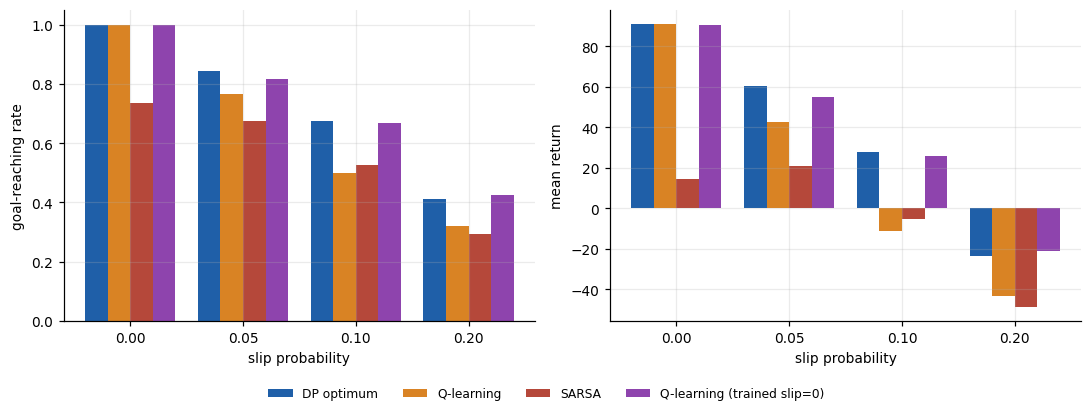

In [8]:
SLIPS = [0.0, 0.05, 0.1, 0.2]
S_SEEDS, S_EPISODES, N_MC = range(10), 3000, 500
sto = {k: {} for k in ["DP optimum", "Q-learning", "SARSA", "Q-learning (trained slip=0)"]}
det_policies = None
for slip in SLIPS:
    e = env.with_slip(slip)
    rng = np.random.default_rng(123)
    Qopt = value_iteration(e, GAMMA)[0]
    sto["DP optimum"][slip] = monte_carlo_eval(e, Qopt, 2000, rng)
    pols = {}
    for algo, key in [("q", "Q-learning"), ("sarsa", "SARSA")]:
        res = []
        pols[algo] = []
        for sd in S_SEEDS:
            Q, _ = train_td(e, algo, S_EPISODES, 0.1, GAMMA, EPS, seed=sd)
            pols[algo].append(Q)
            res.append(monte_carlo_eval(e, Q, N_MC, np.random.default_rng(1000 + sd)))
        sto[key][slip] = {k: float(np.mean([r[k] for r in res])) for k in res[0]}
    if slip == 0.0:
        det_policies = pols["q"]
    res = [monte_carlo_eval(e, Q, N_MC, np.random.default_rng(2000 + i)) for i, Q in enumerate(det_policies)]
    sto["Q-learning (trained slip=0)"][slip] = {k: float(np.mean([r[k] for r in res])) for k in res[0]}

print(f"{'goal rate':32s}" + "".join(f"slip={s:<6}" for s in SLIPS))
for k, v in sto.items():
    print(f"{k:32s}" + "".join(f"{v[s]['goal']:<11.2f}" for s in SLIPS))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
w = 0.2
for i, (k, v) in enumerate(sto.items()):
    for ax, key, lab in zip(axes, ["goal", "ret"], ["goal-reaching rate", "mean return"]):
        ax.bar(np.arange(len(SLIPS)) + (i - 1.5) * w, [v[s][key] for s in SLIPS], w, label=k, color=PALETTE[i if i < 2 else i + 1])
        ax.set(xticks=range(len(SLIPS)), xticklabels=[f"{s:.2f}" for s in SLIPS], xlabel="slip probability", ylabel=lab)
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout(); savefig(fig, "fig_stochastic"); plt.show()
results["stochastic"] = {k: {str(s): v[s] for s in SLIPS} for k, v in sto.items()}

**Observations.** (1) Even the exact optimum degrades quickly: a random step next to a shelf is fatal, so the
DP optimum is the right ceiling for the learners, not 100%. (2) Policies trained without noise transfer very
well. The check below shows why: the optimal policy for slip = 0.1 differs from the deterministic shortest-path
policy in a single square, because in corridors lined with shelves the risk accumulates per step, so the shortest path is
also the safest. (3) Q-learning trained *inside* the noisy environment with α=0.1 does **worse** than the
noise-free policy. The next cell tests the suspected cause: a constant step size leaves a noise floor in the estimates.

In [9]:
e = env.with_slip(0.1)
Q_opt_slip = value_iteration(e, GAMMA)[0]
n_diff = int((Q_opt_slip[fr].argmax(1) != Q_STAR[fr].argmax(1)).sum())
print(f"squares where the slip=0.1 optimum differs from the deterministic optimum: {n_diff}/{len(fr)}")

alpha_check = {}
for alpha, ep in [(0.1, 3000), (0.1, 20000), (0.02, 20000)]:
    g = [monte_carlo_eval(e, train_td(e, "q", ep, alpha, GAMMA, EPS, seed=s)[0], N_MC,
                          np.random.default_rng(100 + s))["goal"] for s in range(6)]
    alpha_check[f"alpha={alpha}, {ep} episodes"] = float(np.mean(g))
    print(f"Q-learning, slip 0.1, alpha={alpha:<5} {ep:>6} episodes -> goal rate {np.mean(g):.3f}")
print(f"exact optimum (DP): {sto['DP optimum'][0.1]['goal']:.3f}")
results["stochastic_alpha"] = dict(n_diff_states=n_diff, goal_rates=alpha_check,
                                   dp_goal=sto["DP optimum"][0.1]["goal"])

squares where the slip=0.1 optimum differs from the deterministic optimum: 1/56


Q-learning, slip 0.1, alpha=0.1     3000 episodes -> goal rate 0.579


Q-learning, slip 0.1, alpha=0.1    20000 episodes -> goal rate 0.494


Q-learning, slip 0.1, alpha=0.02   20000 episodes -> goal rate 0.662
exact optimum (DP): 0.676


More episodes do not help with α=0.1 (the noise floor is set by α, not by the amount of data); a smaller step
size recovers the exact optimum. A decaying α (Robbins-Monro) would do both: learn fast, then average the noise out.

## 8. Policy gradients: REINFORCE with and without a baseline

Instead of a value table, REINFORCE learns a **softmax policy** $\pi_\theta(a\mid s)\propto e^{\theta_{s,a}}$
by following the policy-gradient theorem estimate

$$\nabla_\theta J(\theta)=\mathbb{E}\Big[\sum_t \nabla_\theta\log\pi_\theta(a_t\mid s_t)\,\big(G_t-b(s_t)\big)\Big].$$

The baseline $b(s)$ (here the running mean of returns observed from $s$) does not bias the estimate but
reduces its variance. Settings: α=0.002, 10 000 episodes, 10 seeds.

done in 253s


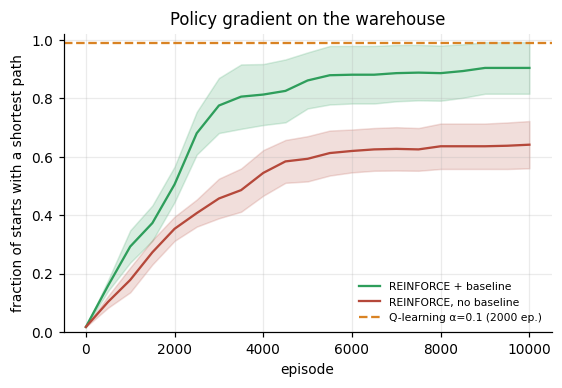

baseline=True : reaches goal 0.93 ±0.08, shortest path 0.90 ±0.09
baseline=False: reaches goal 0.68 ±0.09, shortest path 0.64 ±0.08


In [10]:
RF_EPISODES, RF_SEEDS = 10_000, range(10)
t0 = time.time()
rf = {}
for bl in [True, False]:
    H, F = [], []
    for sd in RF_SEEDS:
        th, h = train_reinforce(env, RF_EPISODES, 0.002, GAMMA, baseline=bl, seed=sd, eval_every=500, dist=DIST)
        H.append(h); F.append(th)
    rf[bl] = (H, F)
print(f"done in {time.time()-t0:.0f}s")

fig, ax = plt.subplots(figsize=(5.2, 3.6))
for bl, col, lab in [(True, PALETTE[2], "REINFORCE + baseline"), (False, PALETTE[3], "REINFORCE, no baseline")]:
    H, _ = rf[bl]
    m, c = mean_ci(np.array([h.eval_optimal for h in H])); ev = H[0].eval_episodes
    ax.plot(ev, m, color=col, label=lab); ax.fill_between(ev, m - c, m + c, color=col, alpha=.18)
m, _ = mean_ci(np.array([h.eval_optimal for h in runs["Q-learning α=0.1"][0]]))
ax.axhline(results["learning"]["Q-learning α=0.1"]["optimal"], color=PALETTE[1], ls="--", label="Q-learning α=0.1 (2000 ep.)")
ax.set(xlabel="episode", ylabel="fraction of starts with a shortest path", ylim=(0, 1.02), title="Policy gradient on the warehouse")
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout(); savefig(fig, "fig_reinforce"); plt.show()

results["reinforce"] = {}
for bl in [True, False]:
    ev = np.array([evaluate_greedy(env, th, DIST) for th in rf[bl][1]])
    (ms, cs), (mo, co) = mean_ci(ev[:, 0]), mean_ci(ev[:, 1])
    results["reinforce"]["baseline" if bl else "no_baseline"] = dict(success=float(ms), success_ci=float(cs),
                                                                    optimal=float(mo), optimal_ci=float(co))
    print(f"baseline={bl!s:5}: reaches goal {ms:.2f} ±{cs:.2f}, shortest path {mo:.2f} ±{co:.2f}")

## 9. Summary

**What the measurements say** (all numbers are means over seeds, with 95% CIs in the table of Section 4)

* **Q-learning solves the deterministic warehouse.** With the original settings it finds a shortest path from
  99.6% of the 56 starts after 2000 episodes (reaching the goal from 100%); with α=0.1,
  98.9%.
* **SARSA is far more fragile**: 22% (α=0.9) and 75% (α=0.1). The cause is not a coding
  error: the exact target $Q^*_\varepsilon$ is optimal, but it is negative on 28 of 56 squares
  (exploring is dangerous here), the margins between actions are small, and rare −100 samples add a lot of noise.
  Its failures are loops (18% of start/seed pairs), not crashes.
* **Policy converges before values.** Greedy policies are optimal while the value tables are still far from their targets.
* **Policy gradient is slower but works:** REINFORCE reaches shortest paths from 90% of
  starts with a baseline against 64% without one, after 10 000 episodes
  (five times more than Q-learning).
* **Noise matters, but not how one might expect.** With a slippery floor even the exact optimum cannot always
  reach the goal (41% at slip 0.2). The optimal policy for slip 0.1 differs from
  the deterministic one in only 1 of 56 squares, so a policy trained without noise transfers almost
  perfectly (67% vs 68% for the exact optimum).
  Training *in* the noisy environment with a constant α=0.1 does worse (50%); a
  smaller α=0.02 recovers 66%.

**Changes compared with the first version of this project**

| First version | This version |
|---|---|
| README announced SARSA, policy gradients, TensorFlow, Pandas | SARSA and REINFORCE are implemented; only NumPy and Matplotlib are used |
| ε was the probability of the *greedy* action | ε is the probability of a random action, as in the report and the literature |
| `np.argmax` on ties always picked "up" | uniform random tie-breaking while learning |
| No cap on path length (possible infinite loop) | step cap in training and evaluation; loops are reported |
| One unseeded run, judged by eye | seeded runs, 20 seeds, exact ground truth (value iteration + BFS) |
| α=0.9 chosen without justification | α, ε, γ sensitivity study |

**Limitations**

* The state space is tiny and tabular, so none of this addresses function approximation (see the report's
  section on continuous states), and the SARSA/Q-learning gap may look different in other environments.
* Hyper-parameters in Sections 4-5 and 7-8 were fixed from the sensitivity study and a small pilot, not tuned
  per algorithm with held-out seeds.
* Confidence intervals are normal approximations over 8-20 seeds.
* ε is constant. An ε schedule (GLIE) is the standard route to making SARSA converge to the true optimum and was
  not explored here.

**Possible extensions:** ε decay, n-step and eligibility-trace methods, a DQN on pixel observations of the same warehouse,
and a multi-robot version.

In [11]:
with open(RES / "results.json", "w") as fh:
    json.dump(results, fh, indent=1, default=float)
print("saved", RES / "results.json")

saved results/results.json
